#Загрузка всех нужно библиотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from tempfile import mkdtemp
from IPython.display import display

pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})
print("pandas:", pd.__version__, "| NumPy:", np.__version__)

pandas: 2.2.3 | NumPy: 2.4.6


#Загрузка датасета и переменной

In [3]:
# Загрузка CSV файла из локального пространство google collab и создание переменной
raw_df = pd.read_csv('https://raw.githubusercontent.com/abylbabool/ML-and-AI-Engineer/refs/heads/main/02_My_Materials_about_Braincode/02_Homework/03_week/amazon_delivery.csv')

In [4]:
# Создание копии датафрейма
df = raw_df.copy()

#2. Загрузка и первое знакомство

In [ ]:
display(df.head(1))
display(df.head())
display(df.head(10))
display(df.tail())
display(df.sample(5, random_state=42))

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys
5,fxuu788413734,22,4.8,17.431668,78.408321,17.461668,78.438321,2022-03-11,21:20:00,21:30:00,Cloudy,Jam,motorcycle,Urban,130,Toys
6,njmo150975311,33,4.7,23.369746,85.339820,23.479746,85.449820,2022-03-04,19:15:00,19:30:00,Fog,Jam,scooter,Metropolitian,200,Toys
7,jvjc772545076,35,4.6,12.352058,76.606650,12.482058,76.736650,2022-03-14,17:25:00,17:30:00,Cloudy,Medium,motorcycle,Metropolitian,160,Snacks
8,uaeb808891380,22,4.8,17.433809,78.386744,17.563809,78.516744,2022-03-20,20:55:00,21:05:00,Stormy,Jam,motorcycle,Metropolitian,170,Electronics
9,bgvc052754213,36,4.2,30.327968,78.046106,30.397968,78.116106,2022-02-12,21:55:00,22:10:00,Fog,Jam,motorcycle,Metropolitian,230,Toys


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
43734,jlxf819993117,30,4.8,26.902328,75.794257,26.912328,75.804257,2022-03-24,11:35:00,11:45:00,Windy,High,motorcycle,Metropolitian,160,Home
43735,aevx342135787,21,4.6,0.000000,0.000000,0.070000,0.070000,2022-02-16,19:55:00,20:10:00,Windy,Jam,motorcycle,Metropolitian,180,Jewelry
43736,xnek760674819,30,4.9,13.022394,80.242439,13.052394,80.272439,2022-03-11,23:50:00,00:05:00,Cloudy,Low,scooter,Metropolitian,80,Home
43737,cynl434665991,20,4.7,11.001753,76.986241,11.041753,77.026241,2022-03-07,13:35:00,13:40:00,Cloudy,High,motorcycle,Metropolitian,130,Kitchen
43738,nsyz997960170,23,4.9,23.351058,85.325731,23.431058,85.405731,2022-03-02,17:10:00,17:15:00,Fog,Medium,scooter,Metropolitian,180,Cosmetics


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
20794,vvgw032244127,29,4.9,11.000762,76.981876,11.050762,77.031876,2022-03-26,17:15:00,17:30:00,Stormy,Medium,motorcycle,Metropolitian,145,Skincare
37635,fvml427733005,33,4.9,22.760072,75.892574,22.870072,76.002574,2022-03-18,17:15:00,17:25:00,Sandstorms,Medium,scooter,Urban,21,Grocery
14700,bphh205146945,26,4.7,0.000000,0.000000,0.040000,0.040000,2022-03-21,14:10:00,14:15:00,Fog,High,motorcycle,Metropolitian,165,Toys
37852,bdxa651837153,27,4.3,19.223840,72.841347,19.333840,72.951347,2022-03-12,19:10:00,19:15:00,Fog,Jam,motorcycle,Urban,200,Skincare
6736,nqdj107406558,20,5.0,13.058616,80.264151,13.108616,80.314151,2022-03-19,21:35:00,21:45:00,Fog,Jam,van,Metropolitian,145,Cosmetics


In [ ]:
print("Соотношение кол-во записей и колонок:", df.shape)
print("Массив наименований колонок:", df.columns.tolist())
print("Наименование и тип данных колонок", df.dtypes)
print("Общая информация о таблице:", df.info())


Соотношение кол-во записей и колонок: (43739, 16)
Массив наименований колонок: ['Order_ID', 'Agent_Age', 'Agent_Rating', 'Store_Latitude', 'Store_Longitude', 'Drop_Latitude', 'Drop_Longitude', 'Order_Date', 'Order_Time', 'Pickup_Time', 'Weather', 'Traffic', 'Vehicle', 'Area', 'Delivery_Time', 'Category']
Наименование и тип данных колонок Order_ID            object
Agent_Age            int64
Agent_Rating       float64
Store_Latitude     float64
Store_Longitude    float64
Drop_Latitude      float64
Drop_Longitude     float64
Order_Date          object
Order_Time          object
Pickup_Time         object
Weather             object
Traffic             object
Vehicle             object
Area                object
Delivery_Time        int64
Category            object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43739 entries, 0 to 43738
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID

#3. Выбор строк, колонок и сортировка

In [ ]:
print(df["Agent_Age"])
print(df[["Agent_Age"]])
print("Тип данных для Serias", type(df["Agent_Age"]), "\nТип данных для DF", type(df[["Agent_Age"]]))


0        37
1        34
2        23
3        38
4        32
         ..
43734    30
43735    21
43736    30
43737    20
43738    23
Name: Agent_Age, Length: 43739, dtype: int64
       Agent_Age
0             37
1             34
2             23
3             38
4             32
...          ...
43734         30
43735         21
43736         30
43737         20
43738         23

[43739 rows x 1 columns]
Тип данных для Serias <class 'pandas.core.series.Series'> 
Тип данных для DF <class 'pandas.core.frame.DataFrame'>


In [ ]:
print(df.iloc[0:5, 0:3])
print(df.iloc[0::5, 0:3])

        Order_ID  Agent_Age  Agent_Rating
0  ialx566343618         37           4.9
1  akqg208421122         34           4.5
2  njpu434582536         23           4.4
3  rjto796129700         38           4.7
4  zguw716275638         32           4.6
            Order_ID  Agent_Age  Agent_Rating
0      ialx566343618         37           4.9
5      fxuu788413734         22           4.8
10     vmau710398846         21           4.7
15     uhfs888375680         35           4.0
20     pbjm971961647         31           4.7
...              ...        ...           ...
43715  lzan335958845         26           4.9
43720  txib370478343         21           4.8
43725  wjsq095299773         32           4.6
43730  spgc082793916         37           4.8
43735  aevx342135787         21           4.6

[8748 rows x 3 columns]


In [ ]:
df.loc[(df["Agent_Age"] <= 30) & (df["Agent_Rating"] >= 4.9), ["Order_ID", "Agent_Age", "Agent_Rating"]]

,Order_ID,Agent_Age,Agent_Rating
25,edrh271340988,27,5.0
39,zqtj827550147,26,4.9
45,rxgx102974679,23,4.9
46,ikas794013321,27,4.9
51,dcdm719150402,25,5.0
...,...,...,...
43724,hlkt353924203,30,4.9
43727,ytod825048116,20,4.9
43732,uftb261665932,28,4.9
43736,xnek760674819,30,4.9


In [ ]:
df.sort_values("Delivery_Time", ascending=False).head(10)[['Order_ID', 'Delivery_Time']]

,Order_ID,Delivery_Time
16487,hxqu970434841,270
35521,qjgd087784527,270
21677,akps636669665,270
24958,fsnr654643805,270
38055,mhpa398953097,270
4851,myis243640595,270
12911,gcai258433443,270
35577,cpsl197444317,270
21662,ancp526801947,270
3558,isil629379093,270


In [ ]:
df.sort_values(["Delivery_Time", "Order_ID"], ascending=[False, True])[["Order_ID", "Agent_Age", "Agent_Rating", "Delivery_Time"]]

,Order_ID,Agent_Age,Agent_Rating,Delivery_Time
21677,akps636669665,37,4.0,270
21662,ancp526801947,31,5.0,270
32572,beus807773771,32,4.1,270
18921,bgbo527996744,33,4.7,270
35803,blhb475377618,33,4.1,270
...,...,...,...,...
10836,xqmd130328789,29,4.7,10
35908,xzru633169943,23,4.7,10
11928,ycqq641036463,22,4.5,10
29736,yicm115669639,30,4.8,10


#4. Качество данных и обоснованная очистка

In [ ]:
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
})
quality.round(2)

,missing_count,missing_pct
Order_ID,0,0.00
Agent_Age,0,0.00
Agent_Rating,54,0.12
Store_Latitude,0,0.00
Store_Longitude,0,0.00
Drop_Latitude,0,0.00
Drop_Longitude,0,0.00
Order_Date,0,0.00
Order_Time,0,0.00
Pickup_Time,0,0.00


In [91]:
print(
    "Дубликаты по Order_ID:", df.duplicated("Order_ID").sum(),
    "\nДубликаты по всем строкам:", df.duplicated().sum()
)

Дубликаты по Order_ID: 0 
Дубликаты по всем строкам: 0


In [87]:
df.loc[(df["Delivery_Time"] <= 0) | (df["Agent_Age"] <= 0), ["Order_ID", "Delivery_Time", "Agent_Age"]]

,Order_ID,Delivery_Time,Agent_Age


#5. Описательная статистика

In [ ]:
df[["Agent_Rating", "Agent_Age"]].describe().round(2)

,Agent_Rating,Agent_Age
count,43685.00,43739.00
mean,4.63,29.57
std,0.33,5.82
min,1.00,15.00
25%,4.50,25.00
50%,4.70,30.00
75%,4.90,35.00
max,6.00,50.00


In [ ]:
df[["Agent_Rating", "Agent_Age"]].quantile([0.25, 0.50, 0.75, 0.90]).round(2)

,Agent_Rating,Agent_Age
0.25,4.5,25.0
0.50,4.7,30.0
0.75,4.9,35.0
0.90,4.9,38.0


In [ ]:
weather_stats = pd.DataFrame({
    "Количество записей": df["Weather"].value_counts(dropna=False),
    "Процент %": (df["Weather"].value_counts(dropna=False, normalize=True) * 100).round(2)
})
print(weather_stats)

            Количество записей  Процент %
Weather                                  
Fog                       7440      17.01
Stormy                    7374      16.86
Cloudy                    7288      16.66
Sandstorms                7245      16.56
Windy                     7223      16.51
Sunny                     7078      16.18
NaN                         91       0.21


#6. Фильтры и сравнение двух выборок

In [18]:
df.loc[
    (
        (df["Category"] == "Cosmetics")
        |
         (df["Category"] == "Sports")
    )
    &
    (
        (df["Area"] == "Urban ")
        |
        (df["Area"] == "Metropolitian ")
    ),
        ["Order_ID", "Category", "Area"]
      ].head(10)

,Order_ID,Category,Area
2,njpu434582536,Sports,Urban
3,rjto796129700,Cosmetics,Metropolitian
10,vmau710398846,Cosmetics,Metropolitian
16,vmfv999642595,Cosmetics,Metropolitian
25,edrh271340988,Cosmetics,Urban
27,gzfn634029300,Cosmetics,Metropolitian
30,itii428784576,Cosmetics,Urban
34,agoo012263585,Sports,Metropolitian
43,rpuq263118672,Cosmetics,Metropolitian
50,yakw330215137,Cosmetics,Metropolitian


In [ ]:
df.loc[
    (df["Category"].isin(["Cosmetics", "Sports"]))
    &
    (df["Area"].isin(["Urban ", "Metropolitian "])),
    [ "Order_ID", "Category", "Area"]
].head()

,Order_ID,Category,Area
2,njpu434582536,Sports,Urban
3,rjto796129700,Cosmetics,Metropolitian
10,vmau710398846,Cosmetics,Metropolitian
16,vmfv999642595,Cosmetics,Metropolitian
25,edrh271340988,Cosmetics,Urban


In [7]:
group_young = df.loc[df["Agent_Age"] <= 35]
group_old = df.loc[df["Agent_Age"] > 35]
young_or_old = pd.DataFrame({
    "Молодые": [
        len(group_young),
        group_young["Agent_Rating"].count(),
        group_young["Agent_Rating"].mean(),
        group_young["Agent_Rating"].median(),
        group_young["Agent_Rating"].min(),
        group_young["Agent_Rating"].max(),
        group_young["Agent_Rating"].std()
    ],
    "Старшие": [
        len(group_old),
        group_old["Agent_Rating"].count(),
        group_old["Agent_Rating"].mean(),
        group_old["Agent_Rating"].median(),
        group_old["Agent_Rating"].min(),
        group_old["Agent_Rating"].max(),
        group_old["Agent_Rating"].std()
    ]
}, index=[
    "Количество строк",
    "Известных рейтингов",
    "Средний рейтинг",
    "Медианный рейтинг",
    "Минимальный рейтинг",
    "Максимальный рейтинг",
    "Стандартное отклонение"
])
display(young_or_old.round(2))


,Молодые,Старшие
Количество строк,34836.00,8903.00
Известных рейтингов,34794.00,8891.00
Средний рейтинг,4.64,4.60
Медианный рейтинг,4.70,4.70
Минимальный рейтинг,1.00,3.00
Максимальный рейтинг,5.00,6.00
Стандартное отклонение,0.33,0.35


In [95]:
group_young = df.loc[df["Agent_Age"] <= 40]
group_old = df.loc[df["Agent_Age"] > 40]
young_or_old = pd.DataFrame({
    "Молодые": [
        len(group_young),
        group_young["Agent_Rating"].count(),
        group_young["Agent_Rating"].mean(),
        group_young["Agent_Rating"].median(),
        group_young["Agent_Rating"].min(),
        group_young["Agent_Rating"].max(),
        group_young["Agent_Rating"].std()
    ],
    "Старшие": [
        len(group_old),
        group_old["Agent_Rating"].count(),
        group_old["Agent_Rating"].mean(),
        group_old["Agent_Rating"].median(),
        group_old["Agent_Rating"].min(),
        group_old["Agent_Rating"].max(),
        group_old["Agent_Rating"].std()
    ]
}, index=[
    "Количество строк",
    "Известных рейтингов",
    "Средний рейтинг",
    "Медианный рейтинг",
    "Минимальный рейтинг",
    "Максимальный рейтинг",
    "Стандартное отклонение"
])
display(young_or_old.round(2))


,Молодые,Старшие
Количество строк,43686.00,53.0
Известных рейтингов,43632.00,53.0
Средний рейтинг,4.63,6.0
Медианный рейтинг,4.70,6.0
Минимальный рейтинг,1.00,6.0
Максимальный рейтинг,5.00,6.0
Стандартное отклонение,0.33,0.0


#7. Новый признак и групповой отчёт

In [19]:
df["Delivery_Time_in_hours"] = df["Delivery_Time"] / 60
df.head().round(2)

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,...,Traffic,Vehicle,Area,Delivery_Time,Category,Delivery_Time_in_hours
0,ialx566343618,37,4.9,22.75,75.89,22.77,...,High,motorcycle,Urban,120,Clothing,2.00
1,akqg208421122,34,4.5,12.91,77.68,13.04,...,Jam,scooter,Metropolitian,165,Electronics,2.75
2,njpu434582536,23,4.4,12.91,77.68,12.92,...,Low,motorcycle,Urban,130,Sports,2.17
3,rjto796129700,38,4.7,11.00,76.98,11.05,...,Medium,motorcycle,Metropolitian,105,Cosmetics,1.75
4,zguw716275638,32,4.6,12.97,80.25,13.01,...,High,scooter,Metropolitian,150,Toys,2.50


In [41]:
orders_by_category = df.groupby("Category", dropna=False).agg(
    orders=("Order_ID", "size"),
    orders_count=("Delivery_Time_in_hours", "count"),
    avg_delivery_time=("Delivery_Time_in_hours", "mean"),
    med_delivery_time=("Delivery_Time_in_hours", "median"),
    sum_delivery_time=("Delivery_Time_in_hours", "sum"),
    min_delivery_time=("Delivery_Time_in_hours", "min"),
    max_delivery_time=("Delivery_Time_in_hours", "max"),
)
display(orders_by_category.sort_values(
    "orders", ascending=False
).round(2))

,orders,orders_count,avg_delivery_time,med_delivery_time,sum_delivery_time,min_delivery_time,max_delivery_time
Category,,,,,,,
Electronics,2849,2849,2.18,2.08,6212.58,0.83,4.5
Books,2824,2824,2.18,2.08,6166.75,0.83,4.5
Jewelry,2802,2802,2.18,2.08,6106.17,0.83,4.5
Toys,2781,2781,2.16,2.08,5997.50,0.83,4.5
Skincare,2772,2772,2.20,2.17,6099.67,0.83,4.5
Snacks,2770,2770,2.20,2.17,6089.58,0.83,4.5
Outdoors,2747,2747,2.18,2.08,6000.33,0.83,4.5
Apparel,2726,2726,2.20,2.17,5999.42,0.83,4.5
Sports,2719,2719,2.20,2.17,5993.00,0.83,4.5


In [47]:
if len(df) == orders_by_category["orders"].sum():
    print("Correctly")
else:
    print("Not correctly")

Correctly


#8. Три осмысленных графика

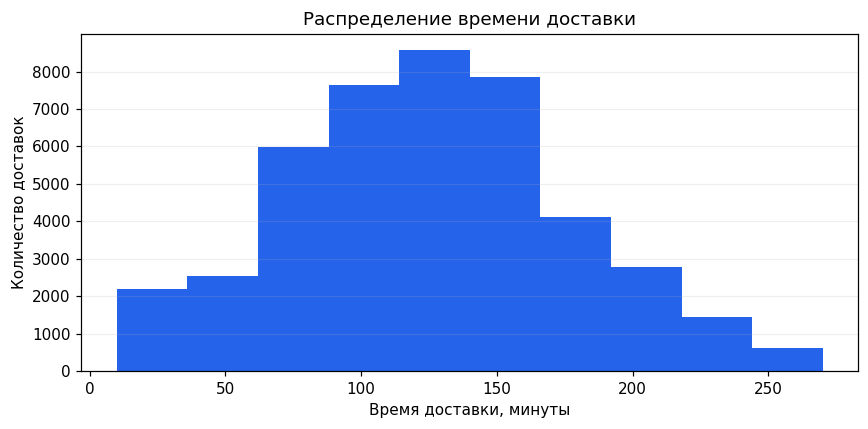

In [85]:
delivery_times = df["Delivery_Time"].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(delivery_times, bins=10, color="#2563EB")
ax.set_title("Распределение времени доставки")
ax.set_xlabel("Время доставки, минуты")
ax.set_ylabel("Количество доставок")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
fig.savefig("delivery_histogram1_1.png")
plt.show()

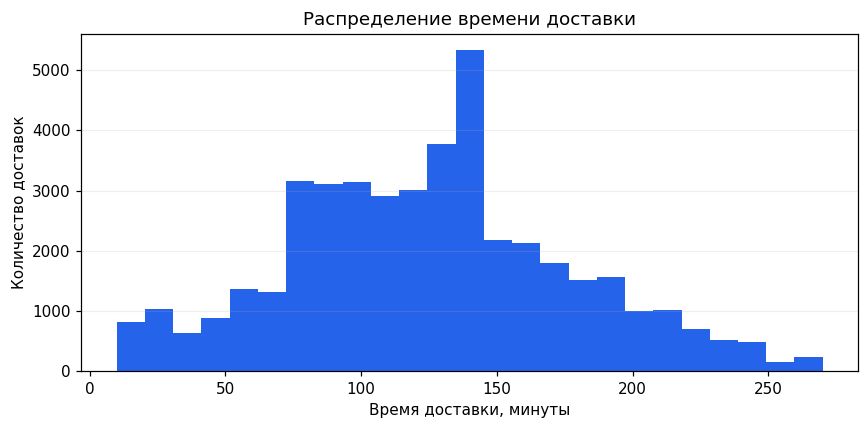

In [84]:
delivery_times = df["Delivery_Time"].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(delivery_times, bins=25, color="#2563EB")
ax.set_title("Распределение времени доставки")
ax.set_xlabel("Время доставки, минуты")
ax.set_ylabel("Количество доставок")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
fig.savefig("delivery_histogram1_2.png")
plt.show()

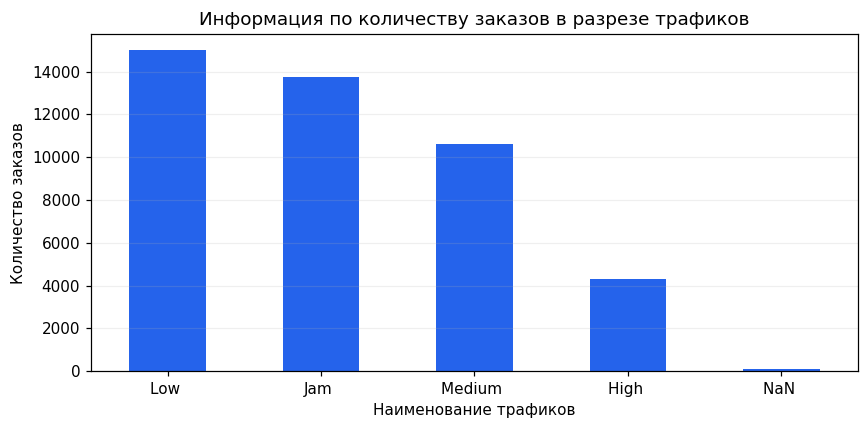

In [94]:
Traffic_dashboard = df["Traffic"].fillna("IDK").value_counts()
ax = Traffic_dashboard.plot.bar(color="#2563EB", rot=0)
ax.set_title("Информация по количеству заказов в разрезе трафиков")
ax.set_xlabel("Наименование трафиков")
ax.set_ylabel("Количество заказов")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
ax.figure.savefig("delivery_histogram2.png")
plt.show()

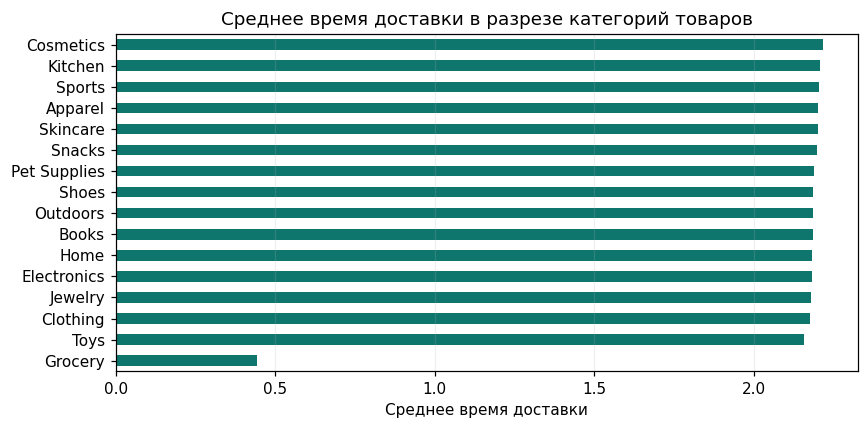

In [93]:
ax = orders_by_category.sort_values("avg_delivery_time", ascending=False).plot.barh(y="avg_delivery_time", legend=False, color="#0F766E")
ax.invert_yaxis()
ax.set_title("Среднее время доставки в разрезе категорий товаров")
ax.set_xlabel("Среднее время доставки")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
ax.figure.savefig("delivery_histogram3.png")
plt.show()